# Stage Five: Context - The Age of the Collectors

The earlier stages show that the cars at the top of the market are getting younger. This notebook asks the follow-up question: **are the collectors getting younger too?**

No auction house publishes the ages of its buyers, so this stage works in two parts:

1. **What has been published.** Hagerty, the largest collector car insurer, reports its customers by generation. These figures are collected in `collector_generations.csv` with their sources.
2. **Whose youth are the top lots from?** A simple lens on our own data: if collectors tend to buy the cars of their teenage years, which generation's teenage years does each top lot come from?

This stage is context, not proof. The figures come from different measures and dates, and part two rests on an assumption that is stated openly below.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")
THEN, NOW = "#7FA3BF", "#B8945A"
GEN_ORDER = ["Silent", "Boomers", "Gen X", "Millennials", "Gen Z"]
GEN_COLOURS = {"Silent": "#6E6259", "Boomers": "#9DB3C4", "Gen X": "#D9B57A", "Millennials": "#B8945A", "Gen Z": "#8A6A32"}

## Stage Five - Part One: What has been published

In [2]:
gens = pd.read_csv("../data/raw/collector_generations.csv")
gens[["measure", "generation", "value_pct", "period"]]

,measure,generation,value_pct,period
0,Share of Hagerty insurance quotes,Boomers,32,2023
1,Share of Hagerty insurance quotes,Gen X,35,2023
2,Share of Hagerty insurance quotes,Millennials and Gen Z,30,2023
3,Share of Hagerty policies by car count,Boomers,52,2023
4,Share of people insured by Hagerty,Gen X,34,2024-25
5,Share of people insured by Hagerty,Millennials and Gen Z,26,2024-25
6,Share of people insured by Hagerty,Gen Z,8,2024-25
7,Share of insurance applications,Millennials,21,2024
8,Share of insurance applications,Millennials,19,2025
9,Would like to own a classic or collector car,Silent,19,survey


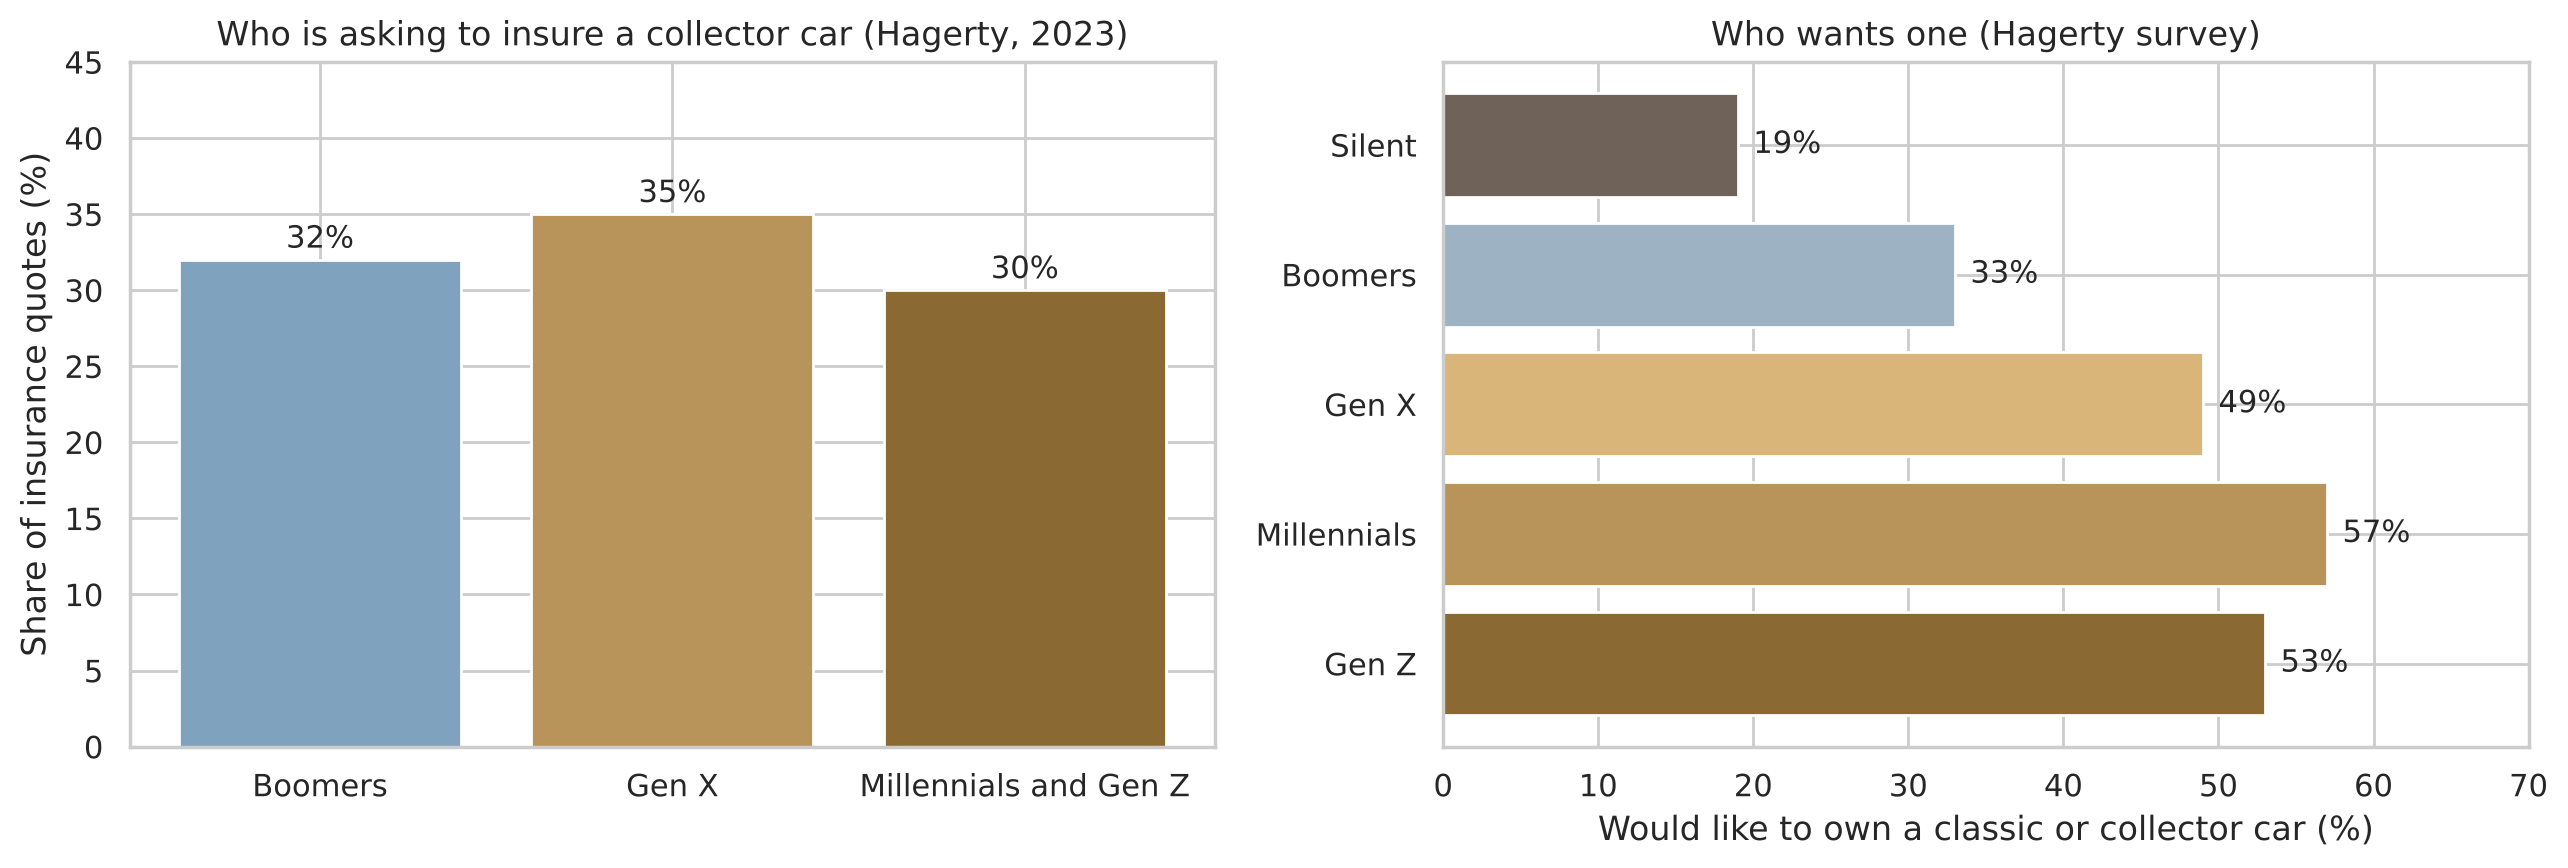

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

q = gens[gens["measure"] == "Share of Hagerty insurance quotes"]
axes[0].bar(q["generation"], q["value_pct"], color=[THEN, NOW, "#8A6A32"])
for i, v in enumerate(q["value_pct"]):
    axes[0].text(i, v + 0.8, f"{v}%", ha="center", fontsize=11)
axes[0].set_ylim(0, 45)
axes[0].set_ylabel("Share of insurance quotes (%)")
axes[0].set_title("Who is asking to insure a collector car (Hagerty, 2023)")

s = (gens[gens["measure"] == "Would like to own a classic or collector car"]
     .set_index("generation").loc[GEN_ORDER].reset_index())
axes[1].barh(s["generation"], s["value_pct"], color=[GEN_COLOURS[g] for g in s["generation"]])
for i, v in enumerate(s["value_pct"]):
    axes[1].text(v + 1, i, f"{v}%", va="center", fontsize=11)
axes[1].invert_yaxis()
axes[1].set_xlim(0, 70)
axes[1].set_xlabel("Would like to own a classic or collector car (%)")
axes[1].set_title("Who wants one (Hagerty survey)")
plt.tight_layout()
plt.savefig("../images/collector_generations.png", dpi=150, bbox_inches="tight")
plt.show()

Three things stand out:

- **Gen X now asks for more insurance quotes than boomers**, and millennials and Gen Z together are close behind.
- **Younger generations want collector cars more.** More than half of millennials and Gen Z say they would like to own one, against a third of boomers.
- **But boomers still own most of the cars.** They hold 52% of Hagerty policies by car count, and their share of new applications actually rose in 2025, while millennials' fell from 21% to 19%.

So the interest is younger, but the money still sits largely with older collectors. Collections are being handed on rather than replaced overnight.

## Stage Five - Part Two: Whose youth are the top lots from?

Collectors are often said to buy the cars they had on their bedroom wall. To test whether the top of the market has moved towards younger collectors' memories, each top lot is given the generation that was **15 years old** in the car's model year.

**Assumption:** the age of 15 is a convention, not a measured fact, and many collectors buy cars from before they were born. The result shows whose teenage years the money is going to, not who actually bought each car.

In [4]:
GEN_BIRTH = [("Before boomers", 1900, 1945), ("Boomers", 1946, 1964), ("Gen X", 1965, 1980),
             ("Millennials", 1981, 1996), ("Gen Z", 1997, 2012)]

def poster_generation(model_year, age=15):
    born = model_year - age
    for name, start, end in GEN_BIRTH:
        if start <= born <= end:
            return name
    return "Gen Z" if born > 2012 else "Before boomers"

lots = pd.read_csv("../data/processed/top_lots_clean.csv")
lots["poster_generation"] = lots["year"].apply(poster_generation)
lots[["when", "year", "car", "price_m", "poster_generation"]].sample(8, random_state=1)

,when,year,car,price_m,poster_generation
42,Then,1967,Ferrari 275 GTB/4 Del Rio,3.800000,Boomers
36,Now,1959,Maserati Tipo 61 Birdcage,4.240000,Before boomers
93,Then,1969,Chevrolet Corvette ZL-1 Convertible,3.140000,Boomers
5,Now,2023,Ferrari Daytona SP3,17.825000,Gen Z
65,Then,1990,Ferrari F40,2.090842,Gen X
108,Now,2012,Ferrari LaFerrari Prototype P2,2.425000,Gen Z
56,Then,1953,Fiat 8V Berlinetta Zagato,2.900000,Before boomers
17,Now,1991,Ferrari F40,8.365000,Gen X


In [5]:
POSTER_ORDER = ["Before boomers", "Boomers", "Gen X", "Millennials", "Gen Z"]
pv = (lots.groupby(["when", "poster_generation"])["price_usd"].sum().unstack()
      .reindex(columns=POSTER_ORDER, fill_value=0).loc[["Then", "Now"]])
poster_share = pv.div(pv.sum(axis=1), axis=0) * 100
poster_share.round(1)

poster_generation,Before boomers,Boomers,Gen X,Millennials,Gen Z
when,,,,,
Then,27.2,45.8,13.5,5.6,7.9
Now,17.3,20.6,14.5,28.0,19.6


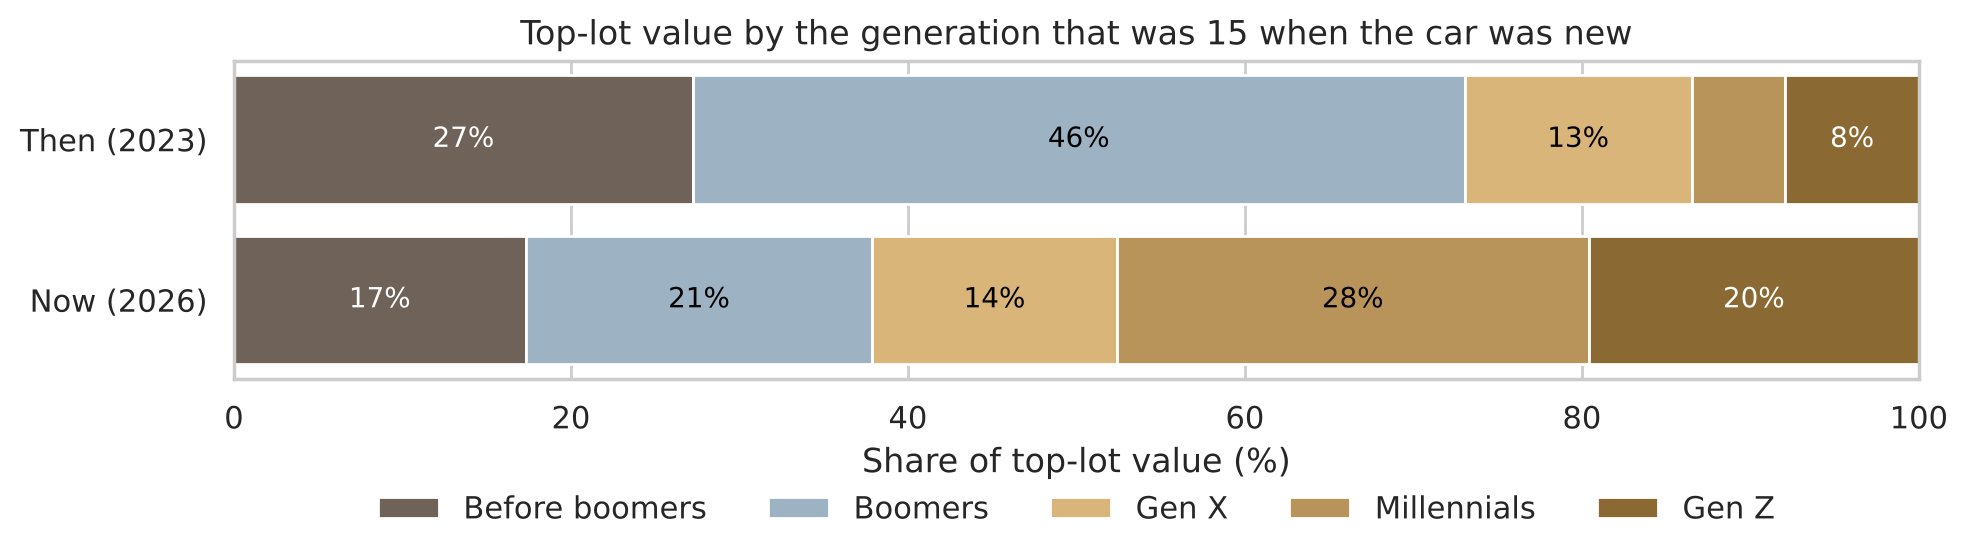

In [6]:
colours = ["#6E6259", "#9DB3C4", "#D9B57A", "#B8945A", "#8A6A32"]
fig, ax = plt.subplots(figsize=(10, 3.2))
left = np.zeros(2)
for g, col in zip(POSTER_ORDER, colours):
    vals = poster_share[g].values
    ax.barh(["Then (2023)", "Now (2026)"], vals, left=left, color=col, label=g)
    for i, v in enumerate(vals):
        if v >= 7:
            ax.text(left[i] + v/2, i, f"{v:.0f}%", ha="center", va="center",
                    color="white" if g in ("Before boomers", "Gen Z") else "black", fontsize=10)
    left += vals
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.set_xlabel("Share of top-lot value (%)")
ax.set_title("Top-lot value by the generation that was 15 when the car was new")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.28), frameon=False)
plt.tight_layout()
plt.savefig("../images/poster_generation.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
gx_m = poster_share.loc[:, ["Gen X", "Millennials", "Gen Z"]].sum(axis=1)
print(f"Share of top-lot value from the teenage years of Gen X and younger: {gx_m['Then']:.0f}% then, {gx_m['Now']:.0f}% now")

Share of top-lot value from the teenage years of Gen X and younger: 27% then, 62% now


## Conclusions

- **The cars have moved faster than the buyers.** Nearly two-thirds of top-lot value now comes from the teenage years of Gen X and younger, up from about a quarter in 2023. Millennials' teenage years alone (cars from 1996 to 2011, such as the F50, Enzo and Carrera GT) take 28%. Yet boomers still hold most of the insured cars, and their share of new applications rose in 2025.
- **Read together**, the most likely picture is a market in handover: younger generations drive interest and set the taste, while older collectors still hold much of the wealth and are reshaping their collections towards the cars now in demand.
- This matters for anyone serving collectors. The next decade is less about finding new buyers than about being present as collections are sold, rebuilt and passed on.

## Limitations

- **Published figures only.** No auction house publishes buyer ages, so Part One relies on Hagerty's insurance and survey data, which covers Hagerty's customers and mostly the US.
- **Mixed measures and dates.** Quote shares, policy counts and survey answers measure different things and come from different years.
- **The age-15 rule is an assumption.** Part Two describes the cars, not the people who bought them.
- **New hypercars land in Gen Z.** Cars built from 2012 on, such as the LaFerrari or a new Bugatti, are counted as Gen Z's teenage years, though they are bought new by wealthy collectors of any age. Read that slice as "new cars" rather than as Gen Z demand.
- **The 1980 line.** Gen X begins with cars from 1980, so the Gen X-and-younger share matches the share of value from cars built since 1980 in Stage Three.